<a href="https://colab.research.google.com/github/2303a51210/quantum_computing_project/blob/main/QGRNN_Complete_Project_30.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Complete QGRNN Node Reconstruction Project

This notebook trains and evaluates a Quantum Graph Recurrent Neural Network on:
- **D34:** Four-node path graph diffusion signals
- **D35:** Eight-node cycle graph diffusion signals

It generates every requested output:
1. Masked-node RMSE
2. MAE
3. Reconstruction R²
4. Error versus missing fraction
5. Qubits/modes
6. Actual circuit depth
7. Shots used
8. Circuit evaluation counts
9. Training time
10. Inference/generation time

**Dataset required:** upload `qgrnn_node_reconstruction_dataset.zip` when prompted in Cell 2. The ZIP should contain the D34 and D35 train/test CSV files. The notebook uses analytic simulation (`shots=None`) for the trained QGRNN; it does not pretend a separate finite-shot demonstration was used for training.

In [4]:
# CELL 1 — Install dependencies
!pip -q install pennylane networkx scikit-learn pandas numpy matplotlib openpyxl

In [5]:
# CELL 2 — Upload and extract the dataset ZIP
from google.colab import files
import zipfile, os, shutil

DATA_DIR = "/content/qgrnn_data"
os.makedirs(DATA_DIR, exist_ok=True)

uploaded = files.upload()  # Upload qgrnn_node_reconstruction_dataset.zip
zip_files = [name for name in uploaded if name.lower().endswith(".zip")]
if not zip_files:
    raise FileNotFoundError("Please upload qgrnn_node_reconstruction_dataset.zip")

with zipfile.ZipFile(zip_files[0], "r") as zf:
    zf.extractall(DATA_DIR)

print("Dataset extracted to:", DATA_DIR)
print("Files:", sorted(os.listdir(DATA_DIR)))

Saving qgrnn_node_reconstruction_dataset.zip to qgrnn_node_reconstruction_dataset (1).zip
Dataset extracted to: /content/qgrnn_data
Files: ['D34_four_node_path_edges.csv', 'D34_four_node_path_test.csv', 'D34_four_node_path_train.csv', 'D35_eight_node_cycle_edges.csv', 'D35_eight_node_cycle_test.csv', 'D35_eight_node_cycle_train.csv', 'README.txt']


In [6]:
# CELL 3 — Imports, reproducibility, and dataset loading
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import pennylane as qml
import torch
import torch.nn as nn
import time, random, math, os
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from IPython.display import display

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
random.seed(SEED)
DEVICE = torch.device("cpu")


def find_data_file(filename):
    direct = os.path.join(DATA_DIR, filename)
    if os.path.exists(direct):
        return direct
    candidates = [f for f in os.listdir(DATA_DIR)
                  if f.startswith(os.path.splitext(filename)[0])
                  and f.endswith(".csv")]
    if candidates:
        return os.path.join(DATA_DIR, sorted(candidates)[0])
    raise FileNotFoundError(f"Cannot find {filename} in {DATA_DIR}")


def load_sequences(filename, n_nodes):
    df = pd.read_csv(find_data_file(filename))
    required = {"sample_id", "time_step"} | {f"node_{i}" for i in range(n_nodes)}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{filename} is missing columns: {sorted(missing)}")
    sequences = []
    for _, group in df.groupby("sample_id", sort=True):
        group = group.sort_values("time_step")
        sequences.append(group[[f"node_{i}" for i in range(n_nodes)]].to_numpy(np.float32))
    return np.stack(sequences)

D34_train = load_sequences("D34_four_node_path_train.csv", 4)
D34_test  = load_sequences("D34_four_node_path_test.csv", 4)
D35_train = load_sequences("D35_eight_node_cycle_train.csv", 8)
D35_test  = load_sequences("D35_eight_node_cycle_test.csv", 8)

for name, data in [("D34 train", D34_train), ("D34 test", D34_test),
                   ("D35 train", D35_train), ("D35 test", D35_test)]:
    print(f"{name}: {data.shape}")

D34 train: (960, 12, 4)
D34 test: (240, 12, 4)
D35 train: (960, 12, 8)
D35 test: (240, 12, 8)


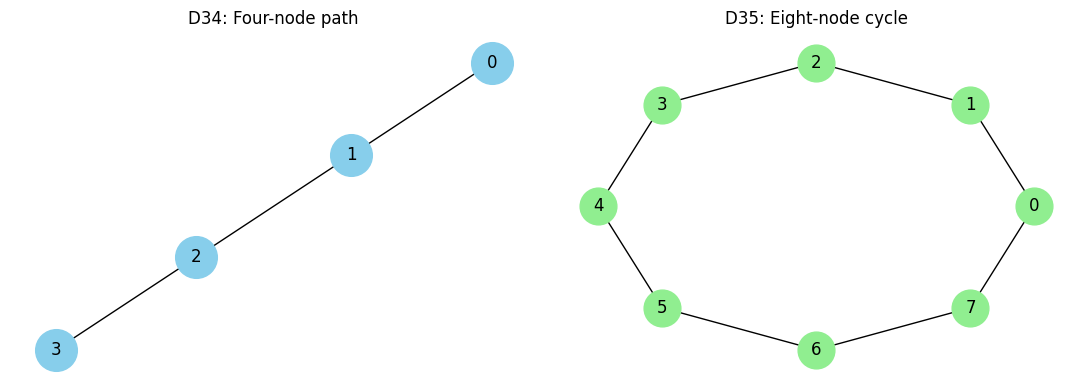

In [7]:
# CELL 4 — Visualize the two graph structures
G34 = nx.path_graph(4)
G35 = nx.cycle_graph(8)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
nx.draw(G34, with_labels=True, node_color="skyblue", node_size=900, ax=axes[0])
axes[0].set_title("D34: Four-node path")
nx.draw_circular(G35, with_labels=True, node_color="lightgreen", node_size=700, ax=axes[1])
axes[1].set_title("D35: Eight-node cycle")
plt.tight_layout(); plt.show()

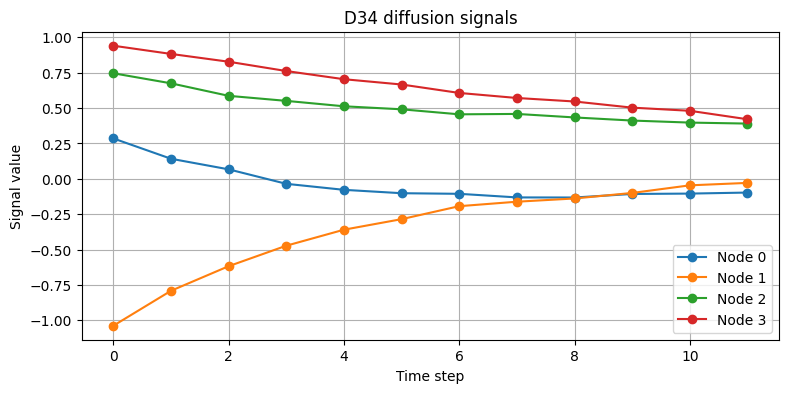

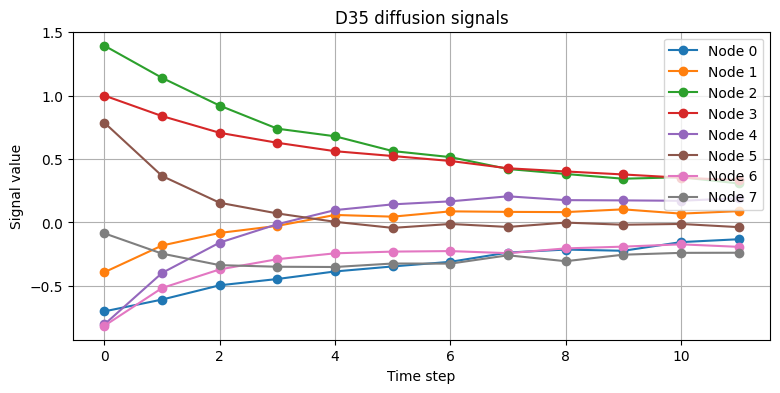

In [8]:
# CELL 5 — Plot example diffusion signals
def plot_signals(data, title):
    plt.figure(figsize=(9, 4))
    for node in range(data.shape[2]):
        plt.plot(data[0, :, node], marker="o", label=f"Node {node}")
    plt.xlabel("Time step"); plt.ylabel("Signal value")
    plt.title(title); plt.grid(True); plt.legend(); plt.show()

plot_signals(D34_train, "D34 diffusion signals")
plot_signals(D35_train, "D35 diffusion signals")

In [9]:
# CELL 6 — Mask generation

def create_mask(batch_size, time_steps, n_nodes, missing_fraction):
    mask = torch.ones(batch_size, time_steps, n_nodes, dtype=torch.float32)
    missing_count = max(1, min(n_nodes - 1, round(n_nodes * missing_fraction)))
    for b in range(batch_size):
        for t in range(time_steps):
            indices = torch.randperm(n_nodes)[:missing_count]
            mask[b, t, indices] = 0.0
    return mask

example = torch.tensor(D34_train[:1])
example_mask = create_mask(1, example.shape[1], 4, 0.5)
print("Original first time step:", example[0, 0])
print("Mask:", example_mask[0, 0])
print("Masked input:", example[0, 0] * example_mask[0, 0])

Original first time step: tensor([ 0.2852, -1.0381,  0.7457,  0.9403])
Mask: tensor([1., 1., 0., 0.])
Masked input: tensor([ 0.2852, -1.0381,  0.0000,  0.0000])


## Model and training

The model uses one qubit per graph node, angle encoding for observed values, mask information and recurrent hidden state, graph-edge CNOT entanglement, and trainable rotation gates. The QNode is configured with `shots=None` and backpropagation.

In [10]:
# CELL 7 — QGRNN model

class QGRNN(nn.Module):
    def __init__(self, n_nodes, edges, n_layers=2):
        super().__init__()
        self.n_nodes = n_nodes
        self.n_layers = n_layers
        self.edges = edges
        self.weights = nn.Parameter(0.1 * torch.randn(n_layers, n_nodes, 2))
        self.scale = nn.Parameter(torch.ones(n_nodes))
        self.bias = nn.Parameter(torch.zeros(n_nodes))
        self.qnode_calls = 0
        self.circuit_input_instances = 0

        dev = qml.device("default.qubit", wires=n_nodes, shots=None)

        @qml.qnode(dev, interface="torch", diff_method="backprop")
        def quantum_circuit(x, mask, hidden, weights):
            wires = range(n_nodes)
            qml.AngleEmbedding(x * np.pi, wires=wires, rotation="Y")
            qml.AngleEmbedding(mask * (np.pi / 2), wires=wires, rotation="X")
            qml.AngleEmbedding(hidden * np.pi, wires=wires, rotation="Z")
            for layer in range(n_layers):
                for i in range(n_nodes):
                    qml.RY(weights[layer, i, 0], wires=i)
                    qml.RZ(weights[layer, i, 1], wires=i)
                for u, v in edges:
                    qml.CNOT(wires=[u, v])
            return tuple(qml.expval(qml.PauliZ(i)) for i in range(n_nodes))

        self.quantum_circuit = quantum_circuit

    def reset_counters(self):
        self.qnode_calls = 0
        self.circuit_input_instances = 0

    def forward(self, x, mask):
        batch_size, time_steps, _ = x.shape
        hidden = torch.zeros(batch_size, self.n_nodes, device=x.device)
        predictions = []
        for t in range(time_steps):
            # One broadcasted QNode call for this batch/time step.
            self.qnode_calls += 1
            self.circuit_input_instances += batch_size
            qout = self.quantum_circuit(x[:, t, :], mask[:, t, :], hidden, self.weights)
            qout = torch.stack(qout, dim=1)
            hidden = qout
            predictions.append(qout * self.scale + self.bias)
        return torch.stack(predictions, dim=1)

print("QGRNN model class created.")

QGRNN model class created.


In [11]:
# CELL 8 — Training configuration and graph edges
EPOCHS = 8
BATCH_SIZE = 16
LEARNING_RATE = 0.01
N_LAYERS = 2
TRAINING_MISSING_FRACTIONS = [0.25, 0.50, 0.75]
EVALUATION_MISSING_FRACTIONS = [0.25, 0.50, 0.75]

def get_edges(graph_type, n_nodes):
    if graph_type == "path":
        return [(i, i + 1) for i in range(n_nodes - 1)]
    if graph_type == "cycle":
        return ([(i, i + 1) for i in range(n_nodes - 1)] + [(n_nodes - 1, 0)])
    raise ValueError("graph_type must be 'path' or 'cycle'")

In [12]:
# CELL 9 — Train the QGRNN and record real QNode/input counts

def train_qgrnn(train_data, n_nodes, graph_type):
    model = QGRNN(n_nodes, get_edges(graph_type, n_nodes), N_LAYERS).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    data = torch.tensor(train_data, dtype=torch.float32)
    n_samples, time_steps, _ = data.shape
    model.reset_counters()
    start_time = time.perf_counter()

    for epoch in range(EPOCHS):
        model.train()
        permutation = torch.randperm(n_samples)
        epoch_losses = []
        for start in range(0, n_samples, BATCH_SIZE):
            idx = permutation[start:start + BATCH_SIZE]
            batch = data[idx]
            fraction = random.choice(TRAINING_MISSING_FRACTIONS)
            mask = create_mask(len(batch), time_steps, n_nodes, fraction)
            optimizer.zero_grad()
            prediction = model(batch * mask, mask)
            missing = 1.0 - mask
            loss = (((prediction - batch) ** 2) * missing).sum() / missing.sum().clamp(min=1)
            loss.backward()
            optimizer.step()
            epoch_losses.append(loss.item())
        print(f"Epoch {epoch + 1}/{EPOCHS} | Loss: {np.mean(epoch_losses):.6f}")

    training_time = time.perf_counter() - start_time
    training_counts = {
        "Training QNode Calls": model.qnode_calls,
        "Training Circuit Input Instances": model.circuit_input_instances
    }
    model.eval()
    return model, training_time, training_counts

print("Training D34...")
model_D34, time_D34, train_counts_D34 = train_qgrnn(D34_train, 4, "path")
print("Training D35...")
model_D35, time_D35, train_counts_D35 = train_qgrnn(D35_train, 8, "cycle")
print("Training completed.")

Training D34...
Epoch 1/8 | Loss: 0.574900
Epoch 2/8 | Loss: 0.417048
Epoch 3/8 | Loss: 0.410786
Epoch 4/8 | Loss: 0.413856
Epoch 5/8 | Loss: 0.410262
Epoch 6/8 | Loss: 0.406762
Epoch 7/8 | Loss: 0.402762
Epoch 8/8 | Loss: 0.403025
Training D35...
Epoch 1/8 | Loss: 0.369750
Epoch 2/8 | Loss: 0.360775
Epoch 3/8 | Loss: 0.357272
Epoch 4/8 | Loss: 0.351971
Epoch 5/8 | Loss: 0.353464
Epoch 6/8 | Loss: 0.360244
Epoch 7/8 | Loss: 0.351042
Epoch 8/8 | Loss: 0.356904
Training completed.


In [13]:
# CELL 10 — Evaluate masked-node reconstruction at multiple missing fractions

def evaluate_model(model, test_data, n_nodes, fractions):
    rows = []
    saved_example = None
    test_tensor = torch.tensor(test_data, dtype=torch.float32)
    model.eval()
    total_inference_seconds = 0.0
    total_qnode_calls = 0
    total_input_instances = 0

    for fraction in fractions:
        all_true, all_pred = [], []
        model.reset_counters()
        start_time = time.perf_counter()
        with torch.no_grad():
            for start in range(0, len(test_tensor), BATCH_SIZE):
                batch = test_tensor[start:start + BATCH_SIZE]
                mask = create_mask(len(batch), batch.shape[1], n_nodes, fraction)
                prediction = model(batch * mask, mask)
                missing = (mask == 0)
                all_true.extend(batch[missing].cpu().numpy().tolist())
                all_pred.extend(prediction[missing].cpu().numpy().tolist())
                if saved_example is None and fraction == fractions[0]:
                    saved_example = (batch[0].cpu().numpy(), prediction[0].cpu().numpy(), mask[0].cpu().numpy())
        elapsed = time.perf_counter() - start_time
        total_inference_seconds += elapsed
        total_qnode_calls += model.qnode_calls
        total_input_instances += model.circuit_input_instances
        y_true, y_pred = np.asarray(all_true), np.asarray(all_pred)
        rows.append({
            "Missing Fraction": fraction,
            "Missing Percentage": 100 * fraction,
            "Masked-node RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "MAE": float(mean_absolute_error(y_true, y_pred)),
            "Reconstruction R2": float(r2_score(y_true, y_pred)),
            "Inference Time (s)": elapsed,
            "Inference QNode Calls": model.qnode_calls,
            "Inference Circuit Input Instances": model.circuit_input_instances
        })

    counts = {
        "Inference QNode Calls": total_qnode_calls,
        "Inference Circuit Input Instances": total_input_instances,
        "Total Inference Time (s)": total_inference_seconds
    }
    return pd.DataFrame(rows), saved_example, counts

results_D34, example_D34, inference_counts_D34 = evaluate_model(
    model_D34, D34_test, 4, EVALUATION_MISSING_FRACTIONS
)
results_D35, example_D35, inference_counts_D35 = evaluate_model(
    model_D35, D35_test, 8, EVALUATION_MISSING_FRACTIONS
)

print("D34 reconstruction metrics:"); display(results_D34.round(6))
print("D35 reconstruction metrics:"); display(results_D35.round(6))

D34 reconstruction metrics:


,Missing Fraction,Missing Percentage,Masked-node RMSE,MAE,Reconstruction R2,Inference Time (s),Inference QNode Calls,Inference Circuit Input Instances
0,0.25,25.0,0.645393,0.498323,-0.000239,2.228194,180,2880
1,0.50,50.0,0.632968,0.491130,0.000864,2.217336,180,2880
2,0.75,75.0,0.639193,0.494407,0.006115,3.157714,180,2880


D35 reconstruction metrics:


,Missing Fraction,Missing Percentage,Masked-node RMSE,MAE,Reconstruction R2,Inference Time (s),Inference QNode Calls,Inference Circuit Input Instances
0,0.25,25.0,0.588981,0.446595,0.004407,4.834844,180,2880
1,0.50,50.0,0.597571,0.450061,0.008972,4.778924,180,2880
2,0.75,75.0,0.595729,0.449265,0.010337,5.820294,180,2880


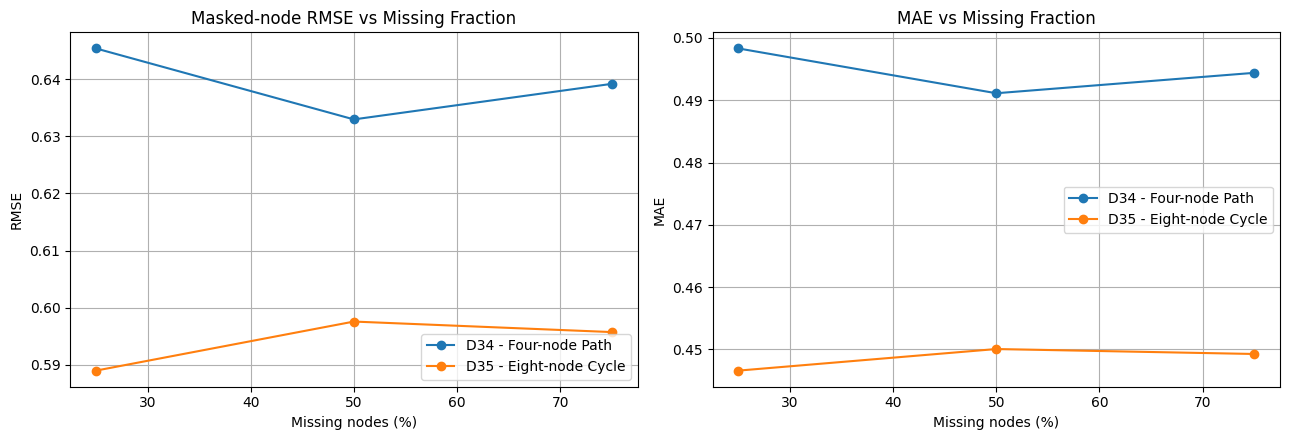

In [14]:
# CELL 11 — Required error-versus-missing-fraction plots
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for label, df in [("D34 - Four-node Path", results_D34), ("D35 - Eight-node Cycle", results_D35)]:
    axes[0].plot(df["Missing Percentage"], df["Masked-node RMSE"], marker="o", label=label)
    axes[1].plot(df["Missing Percentage"], df["MAE"], marker="o", label=label)
axes[0].set(title="Masked-node RMSE vs Missing Fraction", xlabel="Missing nodes (%)", ylabel="RMSE")
axes[1].set(title="MAE vs Missing Fraction", xlabel="Missing nodes (%)", ylabel="MAE")
for ax in axes:
    ax.grid(True); ax.legend()
plt.tight_layout(); plt.show()

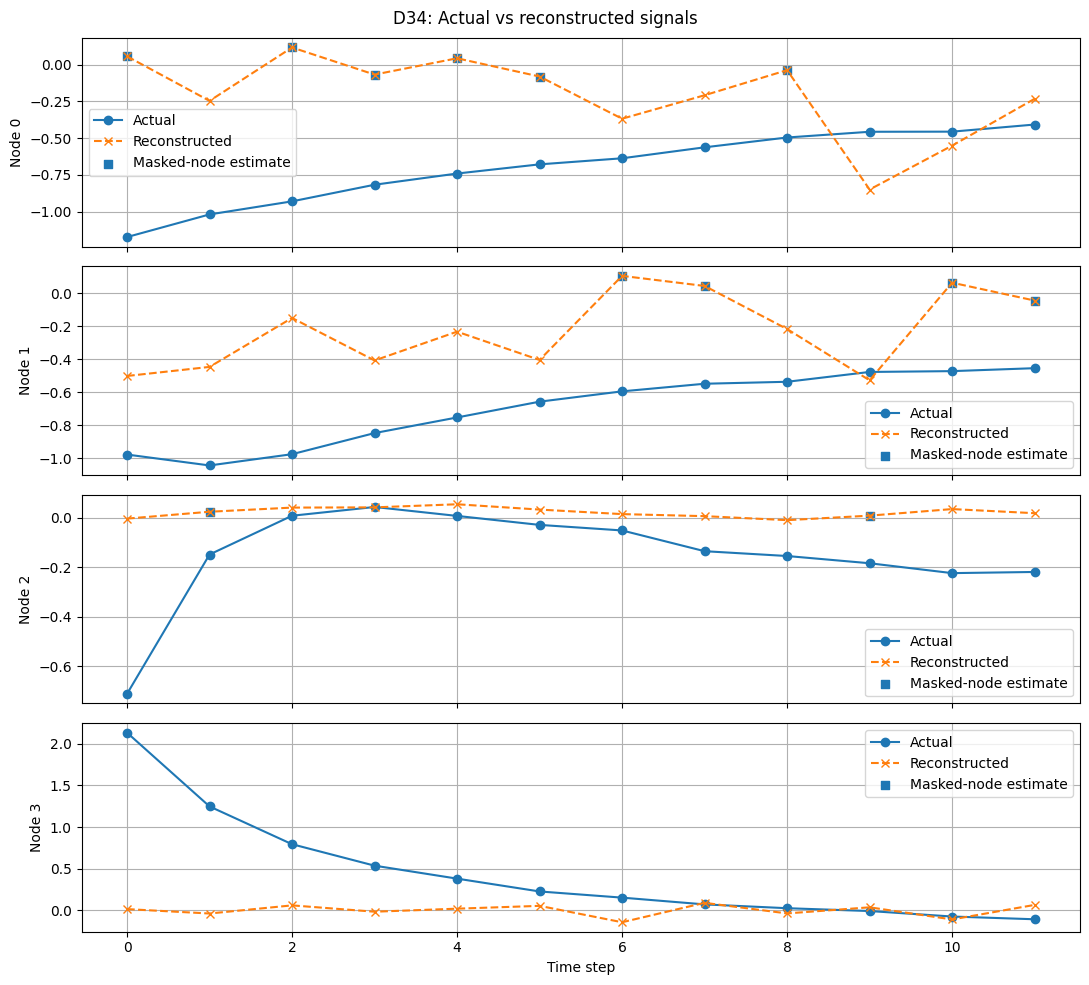

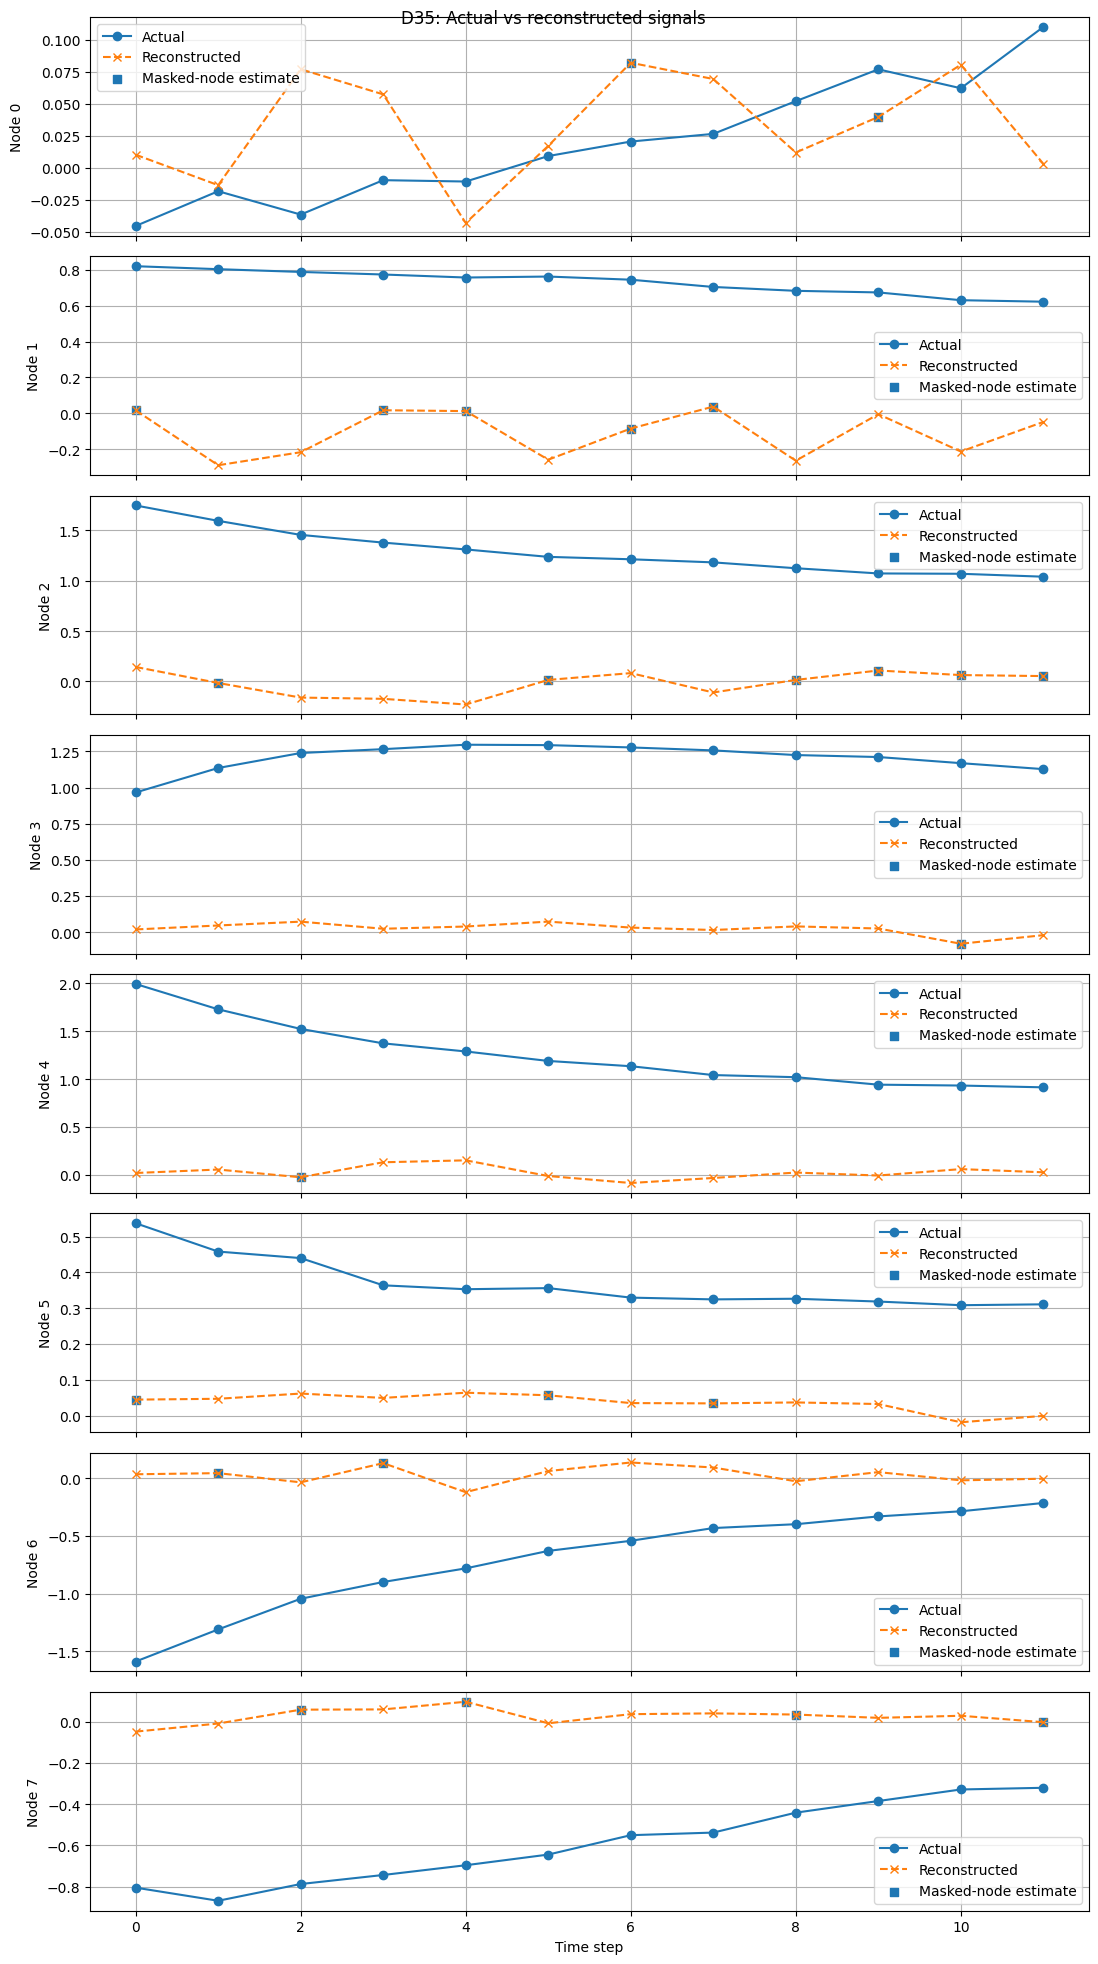

In [15]:
# CELL 12 — Example actual versus reconstructed signals

def plot_reconstruction(example, title):
    actual, predicted, mask = example
    n_nodes = actual.shape[1]
    fig, axes = plt.subplots(n_nodes, 1, figsize=(11, 2.5 * n_nodes), sharex=True)
    if n_nodes == 1: axes = [axes]
    for node in range(n_nodes):
        axes[node].plot(actual[:, node], marker="o", label="Actual")
        axes[node].plot(predicted[:, node], marker="x", linestyle="--", label="Reconstructed")
        missing_t = np.where(mask[:, node] == 0)[0]
        axes[node].scatter(missing_t, predicted[missing_t, node], marker="s", label="Masked-node estimate")
        axes[node].set_ylabel(f"Node {node}"); axes[node].grid(True); axes[node].legend()
    axes[-1].set_xlabel("Time step")
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_reconstruction(example_D34, "D34: Actual vs reconstructed signals")
plot_reconstruction(example_D35, "D35: Actual vs reconstructed signals")

In [16]:
# CELL 13 — Measure actual depth of each trained QNode

def actual_circuit_depth(model):
    n = model.n_nodes
    x = torch.zeros(n, dtype=torch.float32)
    mask = torch.ones(n, dtype=torch.float32)
    hidden = torch.zeros(n, dtype=torch.float32)
    weights = model.weights.detach()
    resource = qml.specs(model.quantum_circuit)(x, mask, hidden, weights)
    return int(resource["resources"].depth)

depth_D34 = actual_circuit_depth(model_D34)
depth_D35 = actual_circuit_depth(model_D35)
print("D34 actual PennyLane circuit depth:", depth_D34)
print("D35 actual PennyLane circuit depth:", depth_D35)

D34 actual PennyLane circuit depth: 12
D35 actual PennyLane circuit depth: 23


In [17]:
# CELL 14 — Complete quantum computational cost table
# These are the actual trained-device settings: shots=None (analytic simulation).
# QNode Calls count Python QNode invocations. Circuit Input Instances count
# broadcasted sample inputs across those calls. Backpropagation is used, so
# parameter-shift gradient evaluations are NOT fabricated or added.

def make_cost_row(label, n_qubits, depth, model, train_time, train_counts, inference_counts):
    shots = model.quantum_circuit.device.shots
    shots_label = "Analytic (shots=None)" if shots is None else str(shots)
    total_calls = train_counts["Training QNode Calls"] + inference_counts["Inference QNode Calls"]
    total_instances = train_counts["Training Circuit Input Instances"] + inference_counts["Inference Circuit Input Instances"]
    return {
        "Dataset": label,
        "Qubits/Modes": n_qubits,
        "Circuit Depth": depth,
        "Shots": shots_label,
        "Training QNode Calls": train_counts["Training QNode Calls"],
        "Training Circuit Input Instances": train_counts["Training Circuit Input Instances"],
        "Inference QNode Calls": inference_counts["Inference QNode Calls"],
        "Inference Circuit Input Instances": inference_counts["Inference Circuit Input Instances"],
        "Total Circuit Evaluations (QNode Calls)": total_calls,
        "Total Circuit Input Instances": total_instances,
        "Gradient Method": "Backpropagation (analytic simulator)",
        "Training Time (s)": train_time,
        "Inference/Generation Time (s)": inference_counts["Total Inference Time (s)"]
    }

quantum_cost = pd.DataFrame([
    make_cost_row("D34 - Four-node Path", 4, depth_D34, model_D34, time_D34, train_counts_D34, inference_counts_D34),
    make_cost_row("D35 - Eight-node Cycle", 8, depth_D35, model_D35, time_D35, train_counts_D35, inference_counts_D35)
])

print("QUANTUM COMPUTATIONAL COST"); display(quantum_cost.round(6))

QUANTUM COMPUTATIONAL COST


,Dataset,Qubits/Modes,Circuit Depth,Shots,Training QNode Calls,Training Circuit Input Instances,Inference QNode Calls,Inference Circuit Input Instances,Total Circuit Evaluations (QNode Calls),Total Circuit Input Instances,Gradient Method,Training Time (s),Inference/Generation Time (s)
0,D34 - Four-node Path,4,12,Shots(total=None),5760,92160,540,8640,6300,100800,Backpropagation (analytic simulator),125.960813,7.603243
1,D35 - Eight-node Cycle,8,23,Shots(total=None),5760,92160,540,8640,6300,100800,Backpropagation (analytic simulator),311.551803,15.434062


In [18]:
# CELL 15 — Combined final reconstruction table
final_reconstruction = pd.concat([
    results_D34.assign(Dataset="D34 - Four-node Path"),
    results_D35.assign(Dataset="D35 - Eight-node Cycle")
], ignore_index=True)
final_reconstruction = final_reconstruction[[
    "Dataset", "Missing Fraction", "Missing Percentage",
    "Masked-node RMSE", "MAE", "Reconstruction R2",
    "Inference Time (s)", "Inference QNode Calls",
    "Inference Circuit Input Instances"
]]

print("FINAL RECONSTRUCTION PERFORMANCE"); display(final_reconstruction.round(6))
print("FINAL QUANTUM COST"); display(quantum_cost.round(6))

FINAL RECONSTRUCTION PERFORMANCE


,Dataset,Missing Fraction,Missing Percentage,Masked-node RMSE,MAE,Reconstruction R2,Inference Time (s),Inference QNode Calls,Inference Circuit Input Instances
0,D34 - Four-node Path,0.25,25.0,0.645393,0.498323,-0.000239,2.228194,180,2880
1,D34 - Four-node Path,0.50,50.0,0.632968,0.491130,0.000864,2.217336,180,2880
2,D34 - Four-node Path,0.75,75.0,0.639193,0.494407,0.006115,3.157714,180,2880
3,D35 - Eight-node Cycle,0.25,25.0,0.588981,0.446595,0.004407,4.834844,180,2880
4,D35 - Eight-node Cycle,0.50,50.0,0.597571,0.450061,0.008972,4.778924,180,2880
5,D35 - Eight-node Cycle,0.75,75.0,0.595729,0.449265,0.010337,5.820294,180,2880


FINAL QUANTUM COST


,Dataset,Qubits/Modes,Circuit Depth,Shots,Training QNode Calls,Training Circuit Input Instances,Inference QNode Calls,Inference Circuit Input Instances,Total Circuit Evaluations (QNode Calls),Total Circuit Input Instances,Gradient Method,Training Time (s),Inference/Generation Time (s)
0,D34 - Four-node Path,4,12,Shots(total=None),5760,92160,540,8640,6300,100800,Backpropagation (analytic simulator),125.960813,7.603243
1,D35 - Eight-node Cycle,8,23,Shots(total=None),5760,92160,540,8640,6300,100800,Backpropagation (analytic simulator),311.551803,15.434062


In [19]:
# CELL 16 — Save every required result to CSV and Excel
OUTPUT_DIR = "/content"
reconstruction_csv = os.path.join(OUTPUT_DIR, "QGRNN_Reconstruction_Metrics.csv")
quantum_csv = os.path.join(OUTPUT_DIR, "QGRNN_Quantum_Cost.csv")
excel_path = os.path.join(OUTPUT_DIR, "QGRNN_Complete_Results.xlsx")

final_reconstruction.to_csv(reconstruction_csv, index=False)
quantum_cost.to_csv(quantum_csv, index=False)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    final_reconstruction.to_excel(writer, sheet_name="Reconstruction Metrics", index=False)
    quantum_cost.to_excel(writer, sheet_name="Quantum Cost", index=False)
    results_D34.to_excel(writer, sheet_name="D34 Detailed Metrics", index=False)
    results_D35.to_excel(writer, sheet_name="D35 Detailed Metrics", index=False)

print("Saved files:")
for path in [reconstruction_csv, quantum_csv, excel_path]:
    print(path, "| exists:", os.path.exists(path), "| bytes:", os.path.getsize(path))

Saved files:
/content/QGRNN_Reconstruction_Metrics.csv | exists: True | bytes: 873
/content/QGRNN_Quantum_Cost.csv | exists: True | bytes: 585
/content/QGRNN_Complete_Results.xlsx | exists: True | bytes: 8221


In [20]:
# CELL 17 — Download complete Excel report
from google.colab import files
files.download("/content/QGRNN_Complete_Results.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Final deliverables checklist

The Excel workbook contains reconstruction metrics (including masked-node RMSE, MAE, R² and error at each missing fraction), quantum resource cost (qubits/modes, measured circuit depth, shots, circuit evaluation counts), and measured training/inference time. The detailed D34 and D35 metrics are also included on separate sheets.

**Interpretation note:** the model is simulated on PennyLane `default.qubit` with analytic expectation values (`shots=None`), not on quantum hardware. The reported QNode call counts and broadcasted input-instance counts are separate quantities. Training time includes the complete training loop; inference time is the measured total across the three evaluation missing fractions.